# Task 2. Character-level Language Modeling

El objetivo de este notebook es reproducir el experimento de modelado de lenguaje a nivel de carácter del paper `Analysis_TCN.pdf`, usando el TCN del repositorio de Shaojie Bai et al.

Los experimentos se ejecutarán en Google Colab. El código fuente se obtiene desde GitHub en `/content/TCN`, mientras que los datos, logs y modelos se conservan en Google Drive:

```text
My Drive/Colab Notebooks/Servicio Grissel/TCN_vs_RNN/Repo_Shaojie/TCN/char_cnn/
```

Se probarán los datasets Penn Treebank (`ptb`) y text8 (`text8`). Cada prueba guardará su salida completa y el tiempo total de ejecución.

## 1. Preparación del entorno

Esta primera etapa comprueba que Colab tiene las bibliotecas necesarias. No entrenaremos ningún modelo todavía.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"Dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

Python: 3.13.16
NumPy: 2.1.3
PyTorch: 2.11.0+cu130
Dispositivo: cuda


In [2]:
# Montar Google Drive y preparar las rutas de trabajo.
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

DRIVE_CHAR_DIR = Path('/content/drive/My Drive/Colab Notebooks/Servicio Grissel/TCN_vs_RNN/Repo_Shaojie/TCN/char_cnn')
DRIVE_CHAR_DIR.mkdir(parents=True, exist_ok=True)
REPO_CHAR_DIR = Path('/content/TCN/TCN/char_cnn')

print(f'Archivos persistentes: {DRIVE_CHAR_DIR}')
print(f'Código del repositorio: {REPO_CHAR_DIR}')

Mounted at /content/drive
Archivos persistentes: /content/drive/My Drive/Colab Notebooks/Servicio Grissel/TCN_vs_RNN/Repo_Shaojie/TCN/char_cnn
Código del repositorio: /content/TCN/TCN/char_cnn


## 2. Obtener el repositorio y sus dependencias

El repositorio se clona en `/content/TCN`, tal como en el notebook de `adding_problem`. El `sys.path.insert` debe ejecutarse antes de importar `TCN.char_cnn.model`.

In [3]:
!if [ ! -d /content/TCN/.git ]; then git clone https://github.com/botellopai18/TCN.git /content/TCN; fi
%cd /content/TCN/TCN/char_cnn
!mkdir -p "/content/drive/My Drive/Colab Notebooks/Servicio Grissel/TCN_vs_RNN/Repo_Shaojie/TCN/char_cnn/data"
!if [ ! -e /content/TCN/TCN/char_cnn/data ]; then ln -s "/content/drive/My Drive/Colab Notebooks/Servicio Grissel/TCN_vs_RNN/Repo_Shaojie/TCN/char_cnn/data" /content/TCN/TCN/char_cnn/data; fi
!pip -q install observations unidecode

import sys
sys.path.insert(0, '/content/TCN')

from TCN.char_cnn.model import TCN

Cloning into '/content/TCN'...
remote: Enumerating objects: 154, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 154 (delta 2), reused 7 (delta 2), pack-reused 143 (from 1)
Receiving objects: 100% (154/154), 16.84 MiB | 51.18 MiB/s, done.
Resolving deltas: 100% (63/63), done.
/content/TCN/TCN/char_cnn
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 3. Configuraciones del experimento

El script `char_cnn_test.py` contiene la implementación del experimento. Se mantienen sus hiperparámetros por defecto: `batch_size=32`, `seq_len=400`, `validseqlen=320`, `emsize=100`, `nhid=450`, `levels=3`, `ksize=3`, `dropout=0.1` y `emb_dropout=0.1`.

Para PTB se usa SGD con `lr=4`, que es la configuración por defecto. Para text8 se usa Adam con `lr=0.002`, de acuerdo con la nota del README del repositorio. `EPOCHS` puede reducirse para una prueba rápida, pero debe dejarse en 100 para la réplica completa.

In [4]:
# Comprobar el tamaño del modelo antes de entrenar.
import torch

n_characters_reference = {'ptb': 50, 'text8': 27}
for dataset, n_characters in n_characters_reference.items():
    num_chans = [450] * (3 - 1) + [100]
    model = TCN(100, n_characters, num_chans, kernel_size=3,
                dropout=0.1, emb_dropout=0.1)
    n_parameters = sum(parameter.numel() for parameter in model.parameters())
    print(f'{dataset}: {n_parameters:,} parámetros')

ptb: 2,222,100 parámetros
text8: 2,219,777 parámetros


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


## 4. Ejecutar las pruebas y registrar el tiempo

La función siguiente ejecuta cada prueba, muestra su salida en Colab, guarda el log completo en Drive y añade `TOTAL_ELAPSED_SECONDS` al final del archivo. Los archivos `model.pt` generados por el script se copian también a Drive con nombres específicos por dataset.

In [5]:
import shutil
import subprocess
import time

def run_char_cnn_test(name, arguments):
    log_path = DRIVE_CHAR_DIR / f'{name}.txt'
    command = [sys.executable, 'char_cnn_test.py', *arguments]
    model_path = REPO_CHAR_DIR / 'model.pt'
    if model_path.exists():
        model_path.unlink()
        print(f'Checkpoint local anterior eliminado: {model_path}')

    print(f'\n===== Iniciando {name} =====')
    print('Comando:', ' '.join(command))
    start = time.perf_counter()
    return_code = None
    # Creamos archivo en drive para guardar el log de la ejecución del test.
    with log_path.open('w', encoding='utf-8') as log_file:
        process = subprocess.Popen(
            command, # Comando a ejecut
            cwd=REPO_CHAR_DIR, # /content/TCN/TCN/char_cnn
            stdout=subprocess.PIPE, # Capturamos la salida estándar del proceso
            stderr=subprocess.STDOUT, # Errores
            text=True, # Salida en texto
            bufsize=1 # línea por línea
        )
        assert process.stdout is not None # Se asegura que la salida estándar no sea None
        for line in process.stdout:
            print(line, end='')
            log_file.write(line)
        return_code = process.wait()

    elapsed = time.perf_counter() - start # Tiempo total de ejecución del test
    with log_path.open('a', encoding='utf-8') as log_file: # Agrega al final del log el tiempo total y el código de retorno
        log_file.write(f'\nTOTAL_ELAPSED_SECONDS={elapsed:.3f}\n')
        log_file.write(f'RETURN_CODE={return_code}\n')

    model_path = REPO_CHAR_DIR / 'model.pt'
    saved_model_path = DRIVE_CHAR_DIR / f'{name}_model.pt'

    if return_code == 0 and model_path.exists():
        shutil.copy2(model_path, saved_model_path)
    elif return_code == 0:
        print('La ejecución terminó sin generar un checkpoint; no se copió ningún modelo.')

    print(f'Tiempo total de {name}: {elapsed:.3f} s ({elapsed / 60:.2f} min)')
    print(f'Log guardado en: {log_path}')

    if return_code != 0:
        raise RuntimeError(f'La prueba {name} terminó con código {return_code}')
    return elapsed

In [6]:
# Réplica PTB. Para una prueba rápida se puede cambiar EPOCHS a un valor menor.
EPOCHS = 100
ptb_time = run_char_cnn_test(
    'results_ptb',
    ['--dataset', 'ptb', '--epochs', str(EPOCHS)]
)


===== Iniciando results_ptb =====
Comando: /usr/bin/python3 char_cnn_test.py --dataset ptb --epochs 100
Namespace(batch_size=32, cuda=True, dropout=0.1, emb_dropout=0.1, clip=0.15, epochs=100, ksize=3, levels=3, log_interval=100, lr=4, emsize=100, optim='SGD', nhid=450, validseqlen=320, seq_len=400, seed=1111, dataset='ptb')
>> Downloading data/simple-examples.tgz.part 

>> [1.0 MB/33.3 MB] 3% @642.0 KB/s,[52s remaining, 1s elapsed]        
>> [2.0 MB/33.3 MB] 6% @1.1 MB/s,[29s remaining, 1s elapsed]        
>> [3.0 MB/33.3 MB] 9% @1.5 MB/s,[21s remaining, 2s elapsed]        
>> [4.0 MB/33.3 MB] 12% @1.8 MB/s,[17s remaining, 2s elapsed]        
>> [5.0 MB/33.3 MB] 15% @2.1 MB/s,[14s remaining, 2s elapsed]        
>> [6.0 MB/33.3 MB] 18% @2.5 MB/s,[12s remaining, 2s elapsed]        
>> [7.0 MB/33.3 MB] 21% @2.8 MB/s,[10s remaining, 2s elapsed]        
>> [8.0 MB/33.3 MB] 24% @3.1 MB/s,[9s remaining, 2s elapsed]        
>> [9.0 MB/33.3 MB] 27% @3.4 MB/s,[8s remaining, 2s elapsed]       

In [7]:
# Réplica text8. El README recomienda Adam para este dataset.
text8_time = run_char_cnn_test(
    'results_text8',
    ['--dataset', 'text8', '--optim', 'Adam', '--lr', '0.002',
     '--epochs', str(EPOCHS)]
)

Se truncaron las últimas líneas 5000 del resultado de transmisión.
| epoch  47 |  4800/ 8789 batches | lr 0.00200 | ms/batch  4.85 | loss 1.185 | bpc 1.710
| epoch  47 |  4900/ 8789 batches | lr 0.00200 | ms/batch  4.86 | loss 1.185 | bpc 1.710
| epoch  47 |  5000/ 8789 batches | lr 0.00200 | ms/batch  4.85 | loss 1.206 | bpc 1.740
| epoch  47 |  5100/ 8789 batches | lr 0.00200 | ms/batch  4.85 | loss 1.195 | bpc 1.723
| epoch  47 |  5200/ 8789 batches | lr 0.00200 | ms/batch  4.85 | loss 1.207 | bpc 1.741
| epoch  47 |  5300/ 8789 batches | lr 0.00200 | ms/batch  4.85 | loss 1.201 | bpc 1.732
| epoch  47 |  5400/ 8789 batches | lr 0.00200 | ms/batch  4.85 | loss 1.208 | bpc 1.743
| epoch  47 |  5500/ 8789 batches | lr 0.00200 | ms/batch  4.85 | loss 1.207 | bpc 1.742
| epoch  47 |  5600/ 8789 batches | lr 0.00200 | ms/batch  4.85 | loss 1.216 | bpc 1.754
| epoch  47 |  5700/ 8789 batches | lr 0.00200 | ms/batch  4.85 | loss 1.209 | bpc 1.745
| epoch  47 |  5800/ 8789 batches | lr 0.00

## 5. Resumen de tiempos y curvas de validación/prueba

ptb: 100 épocas; tiempo=420.339 s
text8: 100 épocas; tiempo=5829.564 s


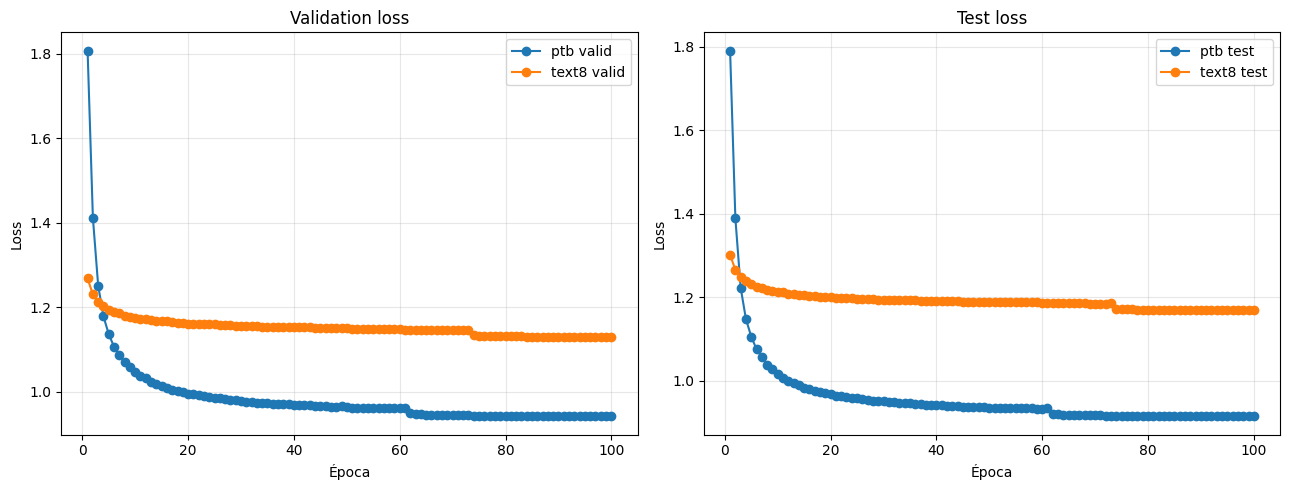

In [8]:
import re
from pathlib import Path
import matplotlib.pyplot as plt

def read_metrics(path):
    text = Path(path).read_text(encoding='utf-8')
    valid = [float(value) for value in re.findall(r'valid loss\s+([0-9.eE+-]+)', text)]
    test = [float(value) for value in re.findall(
        r'^\| End of epoch\s+\d+\s+\| test loss\s+([0-9.eE+-]+)',
        text, flags=re.MULTILINE
    )]
    elapsed_match = re.search(r'TOTAL_ELAPSED_SECONDS=([0-9.eE+-]+)', text)
    elapsed = float(elapsed_match.group(1)) if elapsed_match else None
    return valid, test, elapsed

results = {}
for dataset in ('ptb', 'text8'):
    valid, test, elapsed = read_metrics(DRIVE_CHAR_DIR / f'results_{dataset}.txt')
    results[dataset] = {'valid': valid, 'test': test, 'elapsed': elapsed}
    print(f'{dataset}: {len(valid)} épocas; tiempo={elapsed:.3f} s')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for dataset, values in results.items():
    epochs = range(1, len(values['valid']) + 1)
    axes[0].plot(epochs, values['valid'], marker='o', label=f'{dataset} valid')
    axes[1].plot(epochs, values['test'], marker='o', label=f'{dataset} test')
axes[0].set(title='Validation loss', xlabel='Época', ylabel='Loss')
axes[1].set(title='Test loss', xlabel='Época', ylabel='Loss')
for axis in axes:
    axis.grid(True, alpha=0.3)
    axis.legend()
fig.tight_layout()
plt.show()